# 01 — Exploration des données

**But :** comprendre les données avant de toucher au moindre modèle. Chaque analyse suit le même schéma :

> **On regarde** (un graphique ou un tableau) → **on conclut** (ce que ça montre) → **on décide** (ce qu'on en fait pour la suite).

**Règle de méthode :** ce notebook lit **uniquement les données publiées** par les domaines (`data/ventes/` et `data/service_client/`), jamais la vérité terrain (`data/ground_truth/`). On se met dans la peau d'un analyste réel, qui ne sait pas quelles lignes sont anormales. Les décisions prises ici sont donc légitimes : elles ne « trichent » pas avec les étiquettes.

**Six graphiques seulement**, choisis parce qu'ils apportent une information qu'un tableau ne donne pas. Le reste est présenté sous forme de chiffres et de tableaux. Chaque graphique est enregistré seul, en grand, dans `results/figures/exploration/`, pour être repris dans le mémoire et les slides.

**Sommaire**
1. Premier contact avec les données
2. Qualité de surface : valeurs manquantes et hors référentiel
3. Saisonnalité des ventes
4. Les montants : une distribution très asymétrique
5. Ventes et remboursements : le signe du montant
6. Quantités et segments de clientèle
7. Heures d'achat et canaux
8. Les habitudes de chaque client
9. Les doublons
10. Les prix dans le temps : peut-on voir une dérive ?
11. Le Service client : clients et tickets
12. Synthèse : le tableau des décisions

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=DeprecationWarning)   # avertissement pandas sans effet ici

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from viz import (ROOT, PALETTE, CATEGORY_ORDER, CATEGORY_COLOR, CHANNEL_ORDER, CHANNEL_COLOR,
                 INK_2, MUTED, HIGHLIGHT, PERIOD_FILL, setup, save, euros)

sys.path.insert(0, str(ROOT))
from data_generation import config as C   # paramètres publics : pays, devises, périodes

setup()
pd.set_option("display.max_columns", 20)

# Les données sont régénérées si besoin (même graine, donc mêmes données).
if not (ROOT / "data/ventes/transactions.csv").exists():
    from data_generation.generate import build, write
    write(build(), root=str(ROOT / "data"), summary_path=str(ROOT / "results/metrics/generation_summary.json"))

tx = pd.read_csv(ROOT / "data/ventes/transactions.csv", parse_dates=["date_transaction"])
clients = pd.read_csv(ROOT / "data/service_client/clients_interne.csv")
tickets = pd.read_csv(ROOT / "data/service_client/tickets.csv", parse_dates=["date_ticket"])
print(f"{len(tx):,} transactions · {len(clients):,} fiches clients · {len(tickets):,} tickets".replace(",", " "))

36 364 transactions · 3 060 fiches clients · 4 095 tickets


## 1. Premier contact avec les données

**On regarde** la taille du tableau, le type de chaque colonne et quelques lignes.

In [2]:
print(tx.shape)
display(tx.dtypes.to_frame("type"))
tx.head()

(36364, 11)


,type
transaction_id,object
date_transaction,datetime64[ns]
client_id,object
type_transaction,object
categorie,object
montant,float64
quantite,int64
pays,object
devise,object
segment,object


,transaction_id,date_transaction,client_id,type_transaction,categorie,montant,quantite,pays,devise,segment,canal
0,TXN-00000001,2025-01-01 00:16:13,CLT-000911,vente,Mode,95.75,1,CH,CHF,Particulier,Mobile
1,TXN-00000002,2025-01-01 00:27:16,CLT-001194,vente,Alimentation,21.77,1,ES,EUR,Premium,Mobile
2,TXN-00000003,2025-01-01 01:04:41,CLT-001662,vente,Mode,235.04,11,BE,EUR,Professionnel,Web
3,TXN-00000004,2025-01-01 06:59:18,CLT-000104,vente,Mode,127.66,1,ES,EUR,Particulier,Mobile
4,TXN-00000005,2025-01-01 07:40:23,CLT-002708,vente,Sport,105.92,2,FR,EUR,Premium,Web


**On conclut.** 36 364 transactions et 11 colonnes, exactement celles du contrat n° 1. Les types sont cohérents : la date est bien lue comme une date, le montant comme un nombre décimal, la quantité comme un entier.

**On décide.** Le schéma est conforme au contrat : on peut passer au contenu.

## 2. Qualité de surface : valeurs manquantes et hors référentiel

**On regarde** deux défauts « visibles à l'œil nu » : les cases vides, et les valeurs qui ne font pas partie de la liste autorisée par le contrat (par exemple une catégorie mal écrite).

In [3]:
VALID = {"type_transaction": {"vente", "remboursement"},
         "categorie": set(CATEGORY_ORDER), "pays": set(C.COUNTRIES),
         "segment": set(C.SEGMENTS), "canal": set(CHANNEL_ORDER)}

problems = {}
for col in ["client_id", "montant"]:
    problems[f"{col} — vide"] = tx[col].isna().sum()
for col, allowed in VALID.items():
    problems[f"{col} — hors liste"] = (~tx[col].isin(allowed)).sum()
expected_currency = tx["pays"].map({p: v[1] for p, v in C.COUNTRIES.items()})
problems["devise — incohérente avec le pays"] = (expected_currency.notna() & (tx["devise"] != expected_currency)).sum()
problems = pd.Series(problems).sort_values(ascending=False)
display(problems[problems > 0].rename("lignes concernées").to_frame())

print("Valeurs hors liste rencontrées :")
for col, allowed in VALID.items():
    bad = tx.loc[~tx[col].isin(allowed), col].value_counts()
    if len(bad): print(f"  {col:<17}", bad.to_dict())
print("\nPays × devise :"); display(pd.crosstab(tx["pays"], tx["devise"]))

,lignes concernées
devise — incohérente avec le pays,103
montant — vide,62
client_id — vide,41
canal — hors liste,33
categorie — hors liste,20
pays — hors liste,16


Valeurs hors liste rencontrées :
  categorie         {'Électroniques': 10, 'MODE': 5, 'Jouets': 3, 'electronique': 2}
  pays              {'fr': 6, 'FRA': 6, 'IT': 4}
  canal             {'web': 12, 'Marketplace': 11, 'Téléphone': 10}

Pays × devise :


devise,CHF,EUR,USD
pays,,,
BE,5,4102,5
CH,3629,13,0
DE,4,3537,7
ES,1,2917,4
FR,34,22060,30
FRA,2,4,0
IT,0,4,0
fr,0,6,0


**On conclut.**
- **62 montants et 41 clients manquants** : c'est peu (0,2 % et 0,1 %), mais un montant vide rend la ligne inutilisable pour le chiffre d'affaires.
- **Des valeurs hors liste** : « Électroniques », « MODE », « electronique » (des fautes de saisie), mais aussi « Jouets » et « IT », qui n'existent pas dans le référentiel. Idem pour les canaux (« web », « Marketplace », « Téléphone ») et les pays (« fr », « FRA »).
- **103 devises incohérentes** : de l'USD alors qu'aucun pays du périmètre ne l'utilise, ou de l'EUR pour la Suisse.

**On décide.**
- Ces défauts violent **directement une règle écrite dans le contrat**. Une règle simple suffit pour les attraper, il est inutile d'y mettre de l'IA. Ce sera la **référence simple** de l'étape 4.
- Ces lignes sont **mises en quarantaine avant toute modélisation** : on n'entraîne pas un modèle sur des lignes dont on sait déjà qu'elles sont fausses.
- On ne corrige pas automatiquement « Électroniques » en « Électronique », même si c'est tentant : c'est au propriétaire des données de valider (principe *human-in-the-loop*).

## 3. Saisonnalité des ventes

**On regarde** le nombre de ventes chaque jour de l'année. Chaque point est un jour ; la courbe est la moyenne sur 7 jours, qui lisse le bruit ; les bandes colorées marquent les temps forts du commerce.

In [4]:
sales = tx[tx["type_transaction"] == "vente"]
daily = sales.set_index("date_transaction").resample("D").size()
smooth = daily.rolling(7, center=True).mean()

fig, ax = plt.subplots()
labels = {"soldes_hiver": "Soldes d'hiver", "soldes_ete": "Soldes d'été",
          "black_friday": "Black Friday", "noel": "Noël"}
for p in C.PERIODS:
    ax.axvspan(pd.Timestamp(p.start), pd.Timestamp(p.end) + pd.Timedelta(days=1),
               color=PERIOD_FILL, alpha=0.16, lw=0)
for p, y in zip(C.PERIODS, [0.97, 0.97, 0.97, 0.90]):
    ax.text(pd.Timestamp(p.start), y, labels[p.name], transform=ax.get_xaxis_transform(),
            fontsize=9, color=INK_2, va="top")
ax.scatter(daily.index, daily.values, s=9, color=PALETTE[0], alpha=0.35, lw=0, label="ventes du jour")
ax.plot(smooth.index, smooth.values, color=PALETTE[0], lw=2.2, label="moyenne sur 7 jours")
ax.set_title("Figure 1 — Nombre de ventes par jour en 2025")
ax.set_ylabel("ventes par jour"); ax.set_ylim(0, daily.max() * 1.32)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.08))
print(save(fig, "01_ventes_par_jour")); plt.show()

by_period = sales.assign(jour=sales["date_transaction"].dt.date)
cal = {d: "normale" for d in by_period["jour"].unique()}
for p in C.PERIODS:
    for d in pd.date_range(p.start, p.end).date: cal[d] = p.name
per_day = by_period.groupby("jour").size().rename("ventes").to_frame()
per_day["periode"] = per_day.index.map(cal)
per_day["week_end"] = pd.to_datetime(per_day.index).dayofweek >= 5
display(per_day.groupby("periode")["ventes"].agg(["median", "max"]).round(0))
display(per_day[per_day["periode"] == "normale"].groupby("week_end")["ventes"].median().rename("médiane (jours normaux)"))

results/figures/exploration/01_ventes_par_jour.png


<Figure size 1100x572 with 1 Axes>

,median,max
periode,,
black_friday,177.0,215
noel,142.0,175
normale,80.0,117
soldes_ete,124.0,166
soldes_hiver,124.0,158


week_end
False    76.0
True     94.0
Name: médiane (jours normaux), dtype: float64

**On conclut.**
- Un jour ordinaire, c'est **environ 80 ventes**. Pendant les soldes, on monte autour de 125, à Noël autour de 140, et au **Black Friday on dépasse 175 ventes par jour en médiane** (pic à 215).
- Le **week-end** fait aussi monter les ventes : 94 ventes en médiane contre 76 en semaine, soit **+24 %**.
- Ces hausses sont **prévisibles et légitimes** : ce sont des cas « normaux mais inhabituels ».

**On décide.**
- La détection d'anomalies travaille **ligne par ligne**. Un jour chargé n'est donc pas, en soi, une anomalie, et on ne doit pas le signaler.
- En revanche, la surveillance des **dérives** (mécanisme 2) doit comparer ce qui est comparable : des soldes avec des soldes, un mois ordinaire avec un mois ordinaire. Sinon, chaque période de soldes déclencherait une fausse alerte.

## 4. Les montants : une distribution très asymétrique

**On regarde** d'abord quelques chiffres clés sur les montants des ventes.

In [5]:
amounts = sales.loc[sales["montant"] > 0, "montant"]
print(f"Moyenne : {amounts.mean():.0f} € · médiane : {amounts.median():.0f} € · maximum : {amounts.max():,.0f} €".replace(",", " "))
print(f"Asymétrie (skewness) : {stats.skew(amounts):.1f} sur l'échelle normale, "
      f"{stats.skew(np.log10(amounts)):.2f} après passage au logarithme")
amounts.quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(0).rename("montant (€)").to_frame().T

Moyenne : 328 € · médiane : 75 € · maximum : 50 582 €
Asymétrie (skewness) : 14.0 sur l'échelle normale, 0.84 après passage au logarithme


,0.01,0.25,0.50,0.75,0.99
montant (€),9.0,36.0,75.0,193.0,4662.0


**On conclut.** La **moyenne (328 €) est quatre fois plus grande que la médiane (75 €)**, tirée vers le haut par quelques très gros montants (jusqu'à 50 000 €). L'**asymétrie vaut 14**, alors qu'une distribution symétrique est proche de 0. Sur une échelle normale, un graphique serait illisible : tout serait écrasé à gauche.

Après passage au **logarithme**, où chaque graduation multiplie par 10 (1 €, 10 €, 100 €, etc.), l'asymétrie tombe à **0,8** : la distribution devient presque symétrique.

### Médiane, quartiles et valeurs extrêmes : la boîte à moustaches

La **boîte à moustaches** (*boxplot*) résume une distribution en cinq repères :

- le **trait au milieu de la boîte** : la **médiane** (la moitié des ventes coûte moins, l'autre moitié plus) ;
- les **bords de la boîte** : le **1er quartile** (Q1, 25 % des ventes en dessous) et le **3e quartile** (Q3, 75 % en dessous). La boîte contient donc **la moitié centrale des ventes**, et sa largeur s'appelle l'**écart interquartile** (Q3 − Q1) ;
- les **moustaches** : elles s'étendent jusqu'à la dernière vente située à moins de **1,5 écart interquartile** de la boîte (règle de Tukey) ;
- les **points isolés** au-delà des moustaches : les **valeurs extrêmes**, au sens de cette règle.

**On regarde** les montants de chaque catégorie, sur l'échelle logarithmique.

results/figures/exploration/02_montants_par_categorie.png


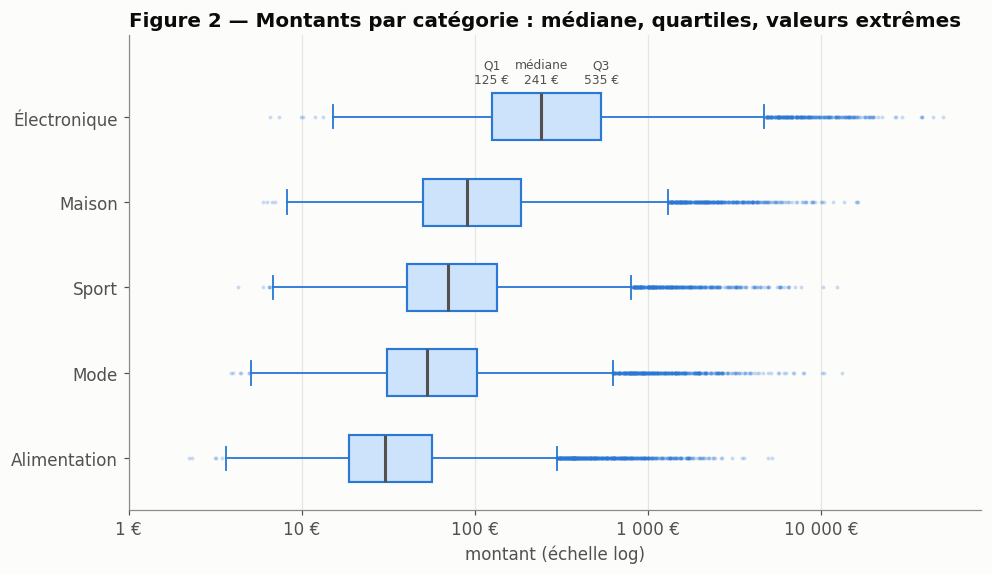

,Q1 (€),médiane (€),Q3 (€),"extrêmes, échelle normale","extrêmes, échelle log"
catégorie,,,,,
Alimentation,19,30,57,13.9 %,8.0 %
Mode,31,53,103,12.8 %,6.1 %
Sport,40,69,134,13.1 %,5.9 %
Maison,50,90,185,13.9 %,5.5 %
Électronique,125,241,535,13.4 %,3.8 %


Valeurs extrêmes selon la règle de Tukey : 4601 ventes (13.4 %) sur l'échelle normale, 2010 (5.9 %) sur l'échelle log


In [6]:
cats = CATEGORY_ORDER
data = [np.log10(sales.loc[(sales["categorie"] == c) & (sales["montant"] > 0), "montant"]) for c in cats]

fig, ax = plt.subplots(figsize=(10, 5.6))
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, whis=1.5,
                medianprops=dict(color=INK_2, lw=2),
                boxprops=dict(facecolor="#cde2fb", edgecolor=PALETTE[0], lw=1.4),
                whiskerprops=dict(color=PALETTE[0], lw=1.2), capprops=dict(color=PALETTE[0], lw=1.2),
                flierprops=dict(marker="o", ms=2.5, mfc=PALETTE[0], mec="none", alpha=0.25))
ax.set_yticks(range(1, len(cats) + 1), cats)
ax.set_xticks([0, 1, 2, 3, 4], ["1 €", "10 €", "100 €", "1 000 €", "10 000 €"])
# Lecture guidée sur la ligne Électronique (la dernière)
q1, med, q3 = np.percentile(data[-1], [25, 50, 75]); y = len(cats)
for x, lab in [(q1, f"Q1\n{10 ** q1:.0f} €"), (med, f"médiane\n{10 ** med:.0f} €"), (q3, f"Q3\n{10 ** q3:.0f} €")]:
    ax.annotate(lab, (x, y + 0.28), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_ylim(0.4, len(cats) + 0.95)
ax.set_title("Figure 2 — Montants par catégorie : médiane, quartiles, valeurs extrêmes")
ax.set_xlabel("montant (échelle log)"); ax.grid(axis="y", visible=False)
print(save(fig, "02_montants_par_categorie")); plt.show()


def tukey_outliers(x):
    q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
    return int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())


rows = []
for c, logs in zip(cats, data):
    raw = 10 ** logs
    rows.append({"catégorie": c, "Q1 (€)": round(np.percentile(raw, 25)), "médiane (€)": round(np.median(raw)),
                 "Q3 (€)": round(np.percentile(raw, 75)),
                 "extrêmes, échelle normale": f"{100 * tukey_outliers(raw.values) / len(raw):.1f} %",
                 "extrêmes, échelle log": f"{100 * tukey_outliers(logs.values) / len(raw):.1f} %"})
display(pd.DataFrame(rows).set_index("catégorie"))
n_raw = sum(tukey_outliers((10 ** l).values) for l in data); n_log = sum(tukey_outliers(l.values) for l in data)
n_all = sum(len(l) for l in data)
print(f"Valeurs extrêmes selon la règle de Tukey : {n_raw} ventes ({100 * n_raw / n_all:.1f} %) sur l'échelle normale, "
      f"{n_log} ({100 * n_log / n_all:.1f} %) sur l'échelle log")

**On conclut.**
- **Chaque catégorie a son propre niveau de prix** : la moitié centrale des ventes d'Alimentation se situe entre 19 et 57 € (médiane 30 €), celle de l'Électronique entre 125 et 535 € (médiane 241 €), soit huit fois plus.
- Sur l'échelle log, **les boîtes ont à peu près la même largeur** d'une catégorie à l'autre : la dispersion des prix est proportionnelle à leur niveau. C'est une raison de plus de travailler en logarithme.
- **Toutes les catégories ont une longue file de points à droite** : ce sont les gros montants, dont une bonne partie sont des commandes de professionnels (section 6).
- **La règle de Tukey classe « extrêmes » 13,4 % des ventes sur l'échelle normale**, et encore **5,9 % sur l'échelle log**. C'est beaucoup trop pour qu'il s'agisse d'erreurs : la plupart sont des ventes légitimes, simplement grosses.

**On décide.**
1. **On travaille sur le logarithme du montant**, et non sur le montant brut. Sinon, les quelques très gros montants écraseraient tout le reste, et les méthodes fondées sur des distances ou des moyennes seraient faussées.
2. **On compare toujours un montant à sa catégorie.** 200 € est banal en Électronique et énorme en Alimentation : une variable « écart à la médiane de la catégorie » est nécessaire.
3. Pour résumer les montants, on utilise la **médiane** plutôt que la moyenne, qui est trop sensible aux extrêmes.
4. La boîte à moustaches est un **outil de description**, pas un détecteur d'anomalies : **« valeur extrême » ne veut pas dire « anomalie »**. Utiliser la règle de Tukey comme filtre enverrait des milliers de ventes correctes en quarantaine.

## 5. Ventes et remboursements : le signe du montant

**On regarde** le signe du montant selon le type de transaction.

In [7]:
sign = np.select([tx["montant"] > 0, tx["montant"] == 0, tx["montant"] < 0], ["positif", "nul", "négatif"], "vide")
display(pd.crosstab(tx["type_transaction"], sign).reindex(columns=["positif", "nul", "négatif", "vide"]))
refunds = tx[tx["type_transaction"] == "remboursement"]
rate = (refunds.groupby("categorie").size() / sales.groupby("categorie").size()).reindex(CATEGORY_ORDER)
print("Taux de remboursement par catégorie :", (100 * rate).round(1).astype(str).add(" %").to_dict())

col_0,positif,nul,négatif,vide
type_transaction,,,,
remboursement,0,0,1890,0
vente,34309,47,56,62


Taux de remboursement par catégorie : {'Alimentation': '0.9 %', 'Mode': '11.3 %', 'Sport': '5.7 %', 'Maison': '4.6 %', 'Électronique': '4.7 %'}


**On conclut.**
- Les **1 890 remboursements sont tous négatifs** : c'est leur nature.
- **103 ventes ont un montant nul ou négatif** : une vente ne peut pas être gratuite ou négative, ce sont des erreurs.
- Le taux de remboursement varie fortement selon la catégorie : environ **11 % pour la Mode** (les vêtements qui ne vont pas), mais **moins de 1 % pour l'Alimentation**.

**On décide.**
- Une règle naïve du type « montant > 0 » produirait **1 890 fausses alertes**. La règle juste est celle du contrat : une vente est positive, un remboursement est négatif.
- On **sépare ventes et remboursements** pour la détection d'anomalies : leurs distributions n'ont rien à voir, et les mélanger brouillerait le modèle.

## 6. Quantités et segments de clientèle

**On regarde** combien d'articles chaque segment achète en une fois.

In [8]:
seg_order = ["Particulier", "Premium", "Professionnel"]
display(sales.groupby("segment")["quantite"].describe()[["50%", "75%", "max"]].reindex(seg_order))
small = sales[sales["segment"] != "Professionnel"]["quantite"].value_counts().sort_index()
print("Particuliers et Premium, nombre de ventes par quantité :", small.to_dict())

,50%,75%,max
segment,,,
Particulier,1.0,1.0,20.0
Premium,1.0,2.0,19.0
Professionnel,15.0,23.0,140.0


Particuliers et Premium, nombre de ventes par quantité : {1: 23285, 2: 5654, 3: 816, 4: 106, 5: 9, 8: 7, 9: 5, 10: 5, 11: 10, 12: 6, 13: 8, 14: 7, 15: 12, 16: 10, 17: 9, 18: 9, 19: 11, 20: 4}


**On conclut.**
- Les **particuliers et les clients Premium** achètent presque toujours 1 ou 2 articles. Au-delà de 4, c'est rarissime (9 ventes à 5 articles).
- Les **professionnels** achètent en gros : 15 articles en médiane, jusqu'à 140.
- **Surprise :** chez les particuliers et les Premium, **103 ventes ont entre 8 et 20 articles**, alors qu'il n'y en a **aucune** à 6 ou 7. Ce « trou » suivi d'un petit groupe isolé est le signe typique d'une **erreur de saisie de quantité**.

**On décide.**
- Une grosse quantité est **normale pour un professionnel** : on juge toujours la quantité **par rapport au segment**.
- On construit une variable **prix unitaire = montant ÷ quantité**. Si la quantité a été mal saisie, le prix par article devient absurdement bas pour la catégorie : c'est ce que le modèle pourra repérer.
- **Point honnête :** une fois vue à l'exploration, cette anomalie pourrait aussi être attrapée par une **règle d'expert** (« plus de 5 articles pour un particulier »). On en tirera une **deuxième référence simple**, enrichie par l'exploration (section 12).

### Le lien entre quantité et montant : le nuage de points

Un **nuage de points** (*scatterplot*) place chaque vente selon deux variables à la fois. Il sert à voir **comment elles varient ensemble**, et à repérer les points qui ne suivent pas la tendance générale.

**On regarde** le montant en fonction de la quantité, pour chaque segment. Les deux axes sont en échelle log, et chaque point est une vente. Les ventes de particuliers et de Premium de 8 articles ou plus sont entourées.

results/figures/exploration/03_quantite_montant.png


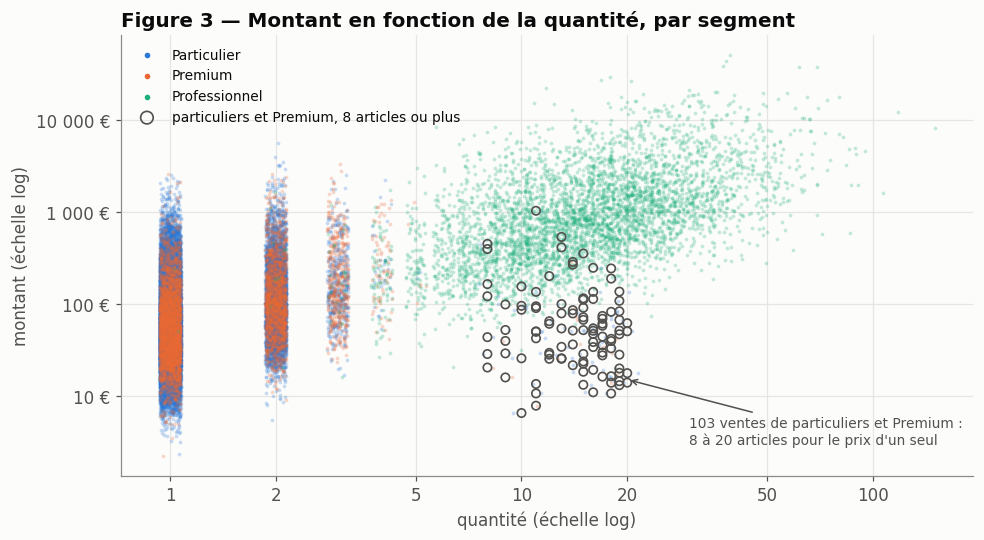

Montant médian de ces 103 ventes : 50 € · montant médian d'une vente d'un article chez un particulier : 52 €


In [9]:
pos_sales = sales[sales["montant"] > 0]
rng = np.random.default_rng(0)
fig, ax = plt.subplots()
for i, seg in enumerate(seg_order):
    d = pos_sales[pos_sales["segment"] == seg]
    jitter = rng.uniform(-0.12, 0.12, len(d))             # léger décalage pour ne pas empiler les entiers
    ax.scatter(d["quantite"] * 10 ** (jitter / 4), d["montant"], s=6, alpha=0.25, lw=0, color=PALETTE[i], label=seg)
ax.set_xscale("log"); euros(ax, "y")
ax.set_xticks([1, 2, 5, 10, 20, 50, 100], ["1", "2", "5", "10", "20", "50", "100"]); ax.minorticks_off()
odd = pos_sales[(pos_sales["segment"] != "Professionnel") & (pos_sales["quantite"] >= 8)]
ax.scatter(odd["quantite"], odd["montant"], s=30, facecolors="none", edgecolors=INK_2, lw=1.1,
           label="particuliers et Premium, 8 articles ou plus")
ax.annotate(f"{len(odd)} ventes de particuliers et Premium :\n8 à 20 articles pour le prix d'un seul",
            (20, 15), xytext=(30, 3), textcoords="data", color=INK_2, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=INK_2))
leg = ax.legend(loc="upper left", markerscale=1.5, fontsize=9)
for h in leg.legend_handles: h.set_alpha(1)
ax.set_title("Figure 3 — Montant en fonction de la quantité, par segment")
ax.set_xlabel("quantité (échelle log)"); ax.set_ylabel("montant (échelle log)")
print(save(fig, "03_quantite_montant")); plt.show()

print(f"Montant médian de ces {len(odd)} ventes : {odd['montant'].median():.0f} € · "
      f"montant médian d'une vente d'un article chez un particulier : "
      f"{pos_sales[(pos_sales['segment'] == 'Particulier') & (pos_sales['quantite'] == 1)]['montant'].median():.0f} €")

**On conclut.**
- Pour les **professionnels**, le montant **monte avec la quantité** : le nuage s'étire en diagonale, de 10 à plus de 100 articles. C'est la tendance attendue (plus d'articles, plus cher).
- Les **particuliers et les Premium** sont concentrés sur 1 à 4 articles.
- **Le petit groupe de 8 à 20 articles chez les particuliers ne suit pas la diagonale** : son montant reste celui d'**un seul article**. Si ces clients avaient vraiment acheté 15 articles, le montant aurait été environ 15 fois plus élevé.

**On décide.**
- Ce nuage confirme qu'il s'agit d'**erreurs de saisie de quantité**, et pas de vrais gros achats.
- Il justifie la variable **prix unitaire = montant ÷ quantité** : c'est exactement la distance d'un point à la diagonale.

## 7. Heures d'achat et canaux

**On regarde** à quelle heure on achète, pour chaque canal. Chaque courbe donne la part des achats du canal faits à chaque heure.

results/figures/exploration/04_heures_par_canal.png


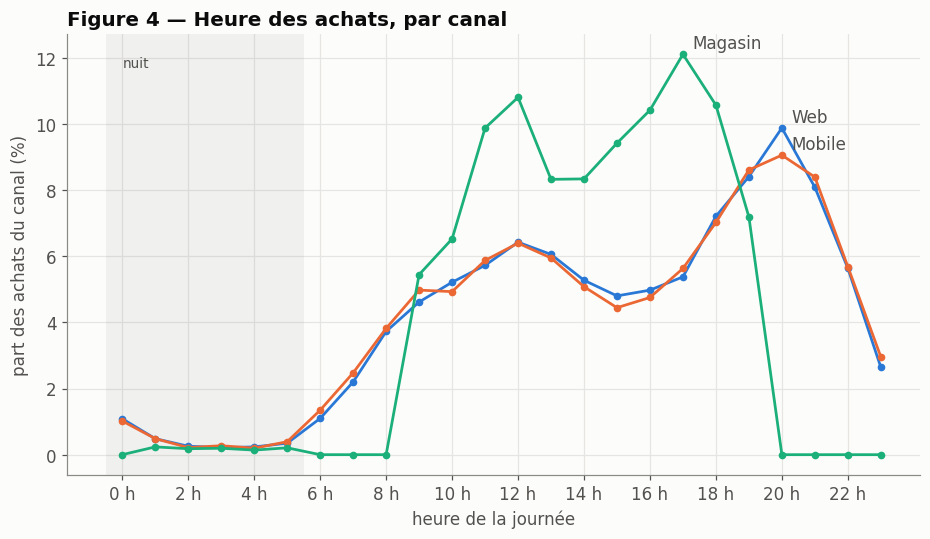

Ventes « en magasin » en dehors des heures d'ouverture (9 h-20 h) : 69
{1: 17, 2: 13, 3: 14, 4: 10, 5: 15}


In [10]:
hour = tx["date_transaction"].dt.hour
fig, ax = plt.subplots()
for ch in CHANNEL_ORDER:
    share = (hour[tx["canal"] == ch].value_counts(normalize=True).reindex(range(24), fill_value=0)) * 100
    ax.plot(share.index, share.values, color=CHANNEL_COLOR[ch], marker="o", ms=4, lw=1.8)
    ax.annotate(ch, (share.idxmax(), share.max()), xytext=(6, 4), textcoords="offset points", color=INK_2)
ax.axvspan(-0.5, 5.5, color=MUTED, alpha=0.10, lw=0)
ax.text(0, 0.95, "nuit", transform=ax.get_xaxis_transform(), color=INK_2, fontsize=9, va="top")
ax.set_xticks(range(0, 24, 2), [f"{h} h" for h in range(0, 24, 2)])
ax.set_title("Figure 4 — Heure des achats, par canal")
ax.set_xlabel("heure de la journée"); ax.set_ylabel("part des achats du canal (%)")
print(save(fig, "04_heures_par_canal")); plt.show()

shop = tx[tx["canal"] == "Magasin"]
night = shop[~shop["date_transaction"].dt.hour.isin(C.STORE_OPENING_HOURS)]
print(f"Ventes « en magasin » en dehors des heures d'ouverture (9 h-20 h) : {len(night)}")
print(night["date_transaction"].dt.hour.value_counts().sort_index().rename("ventes").to_dict())

**On conclut.**
- En **ligne (Web, Mobile)**, on achète toute la journée, avec un pic le soir vers 20 h et un creux la nuit.
- En **magasin**, les achats se concentrent entre 9 h et 20 h, ce qui est logique : ce sont les heures d'ouverture.
- **Surprise :** on trouve **69 ventes « en magasin » entre 1 h et 5 h du matin**, alors que les magasins sont fermés. Le contrat ne dit rien des horaires, donc aucune règle du contrat ne les voit.

**On décide.**
- L'**heure** et le **canal** deviennent des variables du modèle, et surtout leur **combinaison** (une heure banale en ligne peut être impossible en magasin).
- Comme pour les quantités, l'exploration a rendu cette anomalie visible : elle alimentera aussi la **référence enrichie** (« pas de vente en magasin hors des heures d'ouverture »).
- **Proposition pour le contrat :** ajouter cette règle dans la version 1.1 du contrat n° 1. C'est exactement le rôle de la gouvernance fédérée : une découverte sur les données fait évoluer le contrat.

## 8. Les habitudes de chaque client

**On regarde** si un achat est « normal pour ce client ». Pour chaque client qui a au moins 6 achats, on divise chaque montant par la **médiane des achats de ce même client**. Un rapport de 1 veut dire « comme d'habitude », 10 veut dire « dix fois plus que d'habitude ».

results/figures/exploration/05_ecart_habitude_client.png


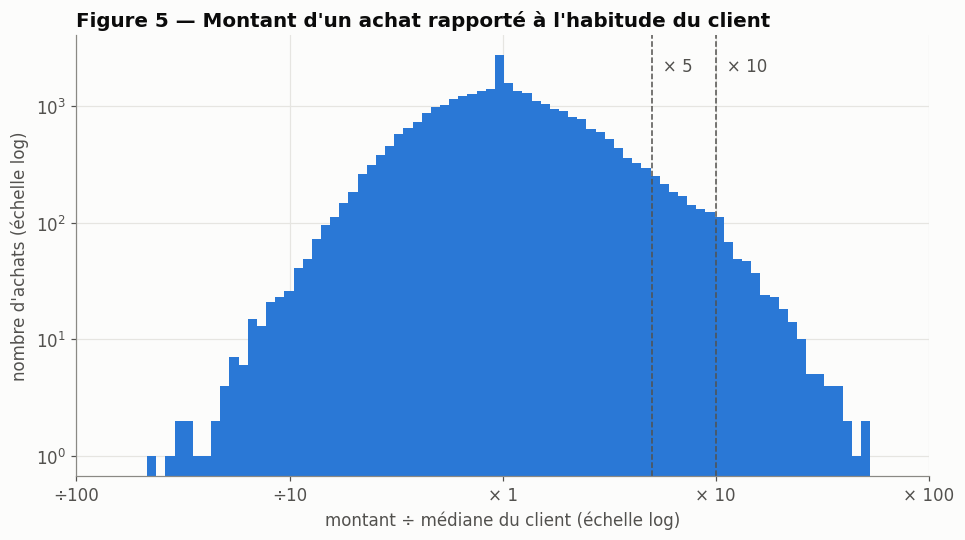

Achats analysés : 30 950
  plus de  3 fois l'habitude du client :  3619  (11.7 %)
  plus de  5 fois l'habitude du client :  1606  (5.2 %)
  plus de 10 fois l'habitude du client :   378  (1.2 %)


In [11]:
pos = sales[sales["montant"] > 0].copy()
pos["n_client"] = pos.groupby("client_id")["montant"].transform("size")
pos["mediane_client"] = pos.groupby("client_id")["montant"].transform("median")
pos = pos[pos["n_client"] >= 6]
ratio = pos["montant"] / pos["mediane_client"]

fig, ax = plt.subplots()
bins = np.logspace(np.log10(ratio.min()), np.log10(ratio.max()), 80)
ax.hist(ratio, bins=bins, color=PALETTE[0])
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([0.01, 0.1, 1, 10, 100], ["÷100", "÷10", "× 1", "× 10", "× 100"]); ax.minorticks_off()
for x in (5, 10):
    ax.axvline(x, color=INK_2, ls="--", lw=1)
    ax.text(x, 0.95, f"  × {x}", transform=ax.get_xaxis_transform(), color=INK_2, va="top")
ax.set_title("Figure 5 — Montant d'un achat rapporté à l'habitude du client")
ax.set_xlabel("montant ÷ médiane du client (échelle log)"); ax.set_ylabel("nombre d'achats (échelle log)")
print(save(fig, "05_ecart_habitude_client")); plt.show()

print(f"Achats analysés : {len(ratio):,}".replace(",", " "))
for k in (3, 5, 10):
    print(f"  plus de {k:>2} fois l'habitude du client : {(ratio > k).sum():>5}  ({100 * (ratio > k).mean():.1f} %)")

**On conclut.**
- La plupart des achats tournent autour de l'habitude du client (× 1), mais **la dispersion naturelle est énorme**. **1 606 achats (environ 5 %) dépassent 5 fois l'habitude** du client, et **378 (un peu plus de 1 %) la dépassent 10 fois**.
- C'est normal : un même client achète un câble à 15 € un jour, et une télévision à 600 € un autre jour.
- Un achat « dix fois plus cher que d'habitude » **n'est donc pas forcément anormal**. Il n'y a pas de frontière nette visible sur ce graphique.

**On décide.**
- L'écart à l'habitude du client est une **variable utile, mais insuffisante seule**. Il faut la combiner avec la catégorie : un gros achat d'Électronique pour un client qui achète d'habitude de l'Électronique est moins suspect.
- C'est précisément le terrain de l'IA : **combiner plusieurs signaux faibles**, là où une règle simple sur un seul critère produirait des centaines de fausses alertes.
- **Attente réaliste :** ce type d'anomalie (« pic client ») sera **le plus difficile à détecter**. On ne promettra pas de miracle.

## 9. Les doublons

**On regarde** le délai entre deux achats successifs **d'un même client, dans une même catégorie**. Un délai de zéro, ou de quelques minutes avec presque le même montant, est suspect. (Le graphique correspondant, plus parlant, est dans le notebook 02, figure 9.)

In [12]:
s = tx.dropna(subset=["client_id"]).sort_values("date_transaction")
g = s.groupby(["client_id", "categorie"])
s = s.assign(delai_min=g["date_transaction"].diff().dt.total_seconds() / 60,
             ecart_montant=(s["montant"] - g["montant"].shift()).abs())
gaps = s["delai_min"].dropna()

bands = pd.cut(s["delai_min"], [-0.1, 0.1, 30, 60 * 24, 60 * 24 * 30, np.inf],
               labels=["délai nul", "moins de 30 min", "30 min à 1 jour", "1 jour à 1 mois", "plus d'un mois"])
display(bands.value_counts().reindex(bands.cat.categories).rename("paires d'achats").to_frame())


exact = tx.duplicated(["client_id", "date_transaction", "categorie", "montant"], keep="first").sum()
near = ((s["delai_min"] > 0) & (s["delai_min"] < 30) & (s["ecart_montant"] <= 1)).sum()
print(f"Doublons exacts (même client, même seconde, même catégorie, même montant) : {exact}")
print(f"Quasi-doublons (moins de 30 min d'écart, moins de 1 € de différence)      : {near}")

,paires d'achats
délai nul,137
moins de 30 min,99
30 min à 1 jour,918
1 jour à 1 mois,14817
plus d'un mois,11646


Doublons exacts (même client, même seconde, même catégorie, même montant) : 137
Quasi-doublons (moins de 30 min d'écart, moins de 1 € de différence)      : 70


**On conclut.**
- **137 achats ont un délai nul** avec l'achat précédent : même client, même seconde, même catégorie, même montant. Ce sont des **doublons exacts**, une double saisie.
- **70 paires d'achats** sont séparées de **moins de 30 minutes**, avec **moins de 1 € d'écart** : ce sont des **quasi-doublons**, la même vente renvoyée avec un arrondi différent.
- Le reste des délais se répartit naturellement entre quelques heures et plusieurs mois.

**On décide.**
- Les doublons exacts : **une règle suffit** (c'est d'ailleurs une règle du contrat).
- Les quasi-doublons échappent à cette règle. On crée deux variables : le **délai depuis l'achat précédent** du client dans la catégorie, et l'**écart de montant** avec cet achat.
- **Attention** : un client peut légitimement racheter le même article. Le seuil (30 minutes, 1 €) ne doit donc pas devenir une règle aveugle. Il sert à alimenter le modèle, et un humain tranche.

## 10. Les prix dans le temps : peut-on voir une dérive ?

**On regarde** l'évolution du **prix unitaire médian** de la catégorie Maison, mois par mois, en France et dans les autres pays (hors professionnels, pour comparer des achats semblables).

results/figures/exploration/06_prix_maison_par_mois.png


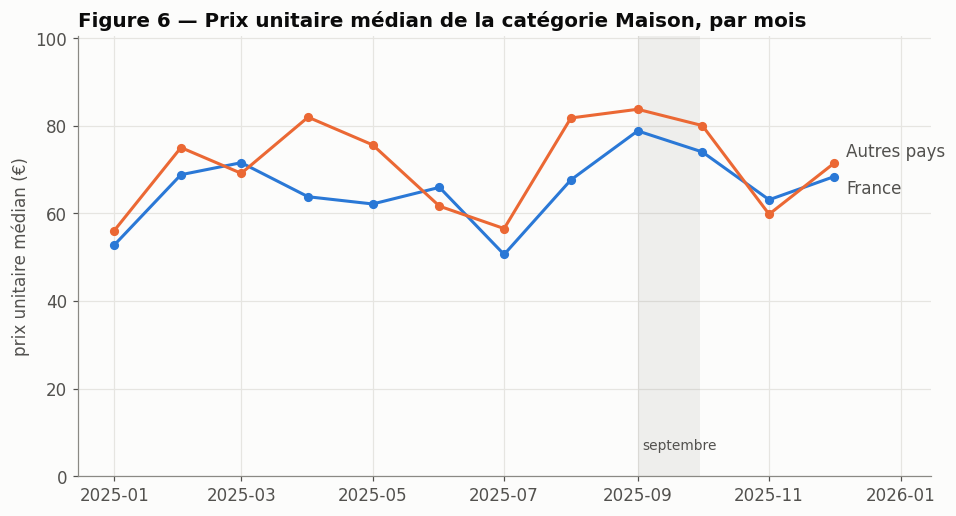

Rapport France / autres pays, mois par mois : {Period('2025-01', 'M'): 0.94, Period('2025-02', 'M'): 0.92, Period('2025-03', 'M'): 1.04, Period('2025-04', 'M'): 0.78, Period('2025-05', 'M'): 0.82, Period('2025-06', 'M'): 1.07, Period('2025-07', 'M'): 0.9, Period('2025-08', 'M'): 0.83, Period('2025-09', 'M'): 0.94, Period('2025-10', 'M'): 0.92, Period('2025-11', 'M'): 1.06, Period('2025-12', 'M'): 0.96}
Amplitude naturelle de ce rapport : de 0.78 à 1.07


In [13]:
home = sales[(sales["categorie"] == "Maison") & (sales["montant"] > 0) & (sales["segment"] != "Professionnel")].copy()
home["prix_unitaire"] = home["montant"] / home["quantite"]
home["zone"] = np.where(home["pays"] == "FR", "France", "Autres pays")
home.loc[home["devise"] == "CHF", "prix_unitaire"] /= C.EUR_TO_CHF        # tout en euros
monthly = home.groupby([home["date_transaction"].dt.to_period("M"), "zone"])["prix_unitaire"].median().unstack()

fig, ax = plt.subplots()
x = monthly.index.to_timestamp()
for i, (zone, dy) in enumerate([("France", -8), ("Autres pays", 8)]):
    ax.plot(x, monthly[zone], marker="o", ms=5, color=PALETTE[i])
    ax.annotate(zone, (x[-1], monthly[zone].iloc[-1]), xytext=(8, dy), textcoords="offset points",
                color=INK_2, va="center")
ax.set_xlim(right=x[-1] + pd.Timedelta(days=45))
ax.axvspan(pd.Timestamp("2025-09-01"), pd.Timestamp("2025-09-30"), color=MUTED, alpha=0.12, lw=0)
ax.text(pd.Timestamp("2025-09-03"), 0.06, "septembre", transform=ax.get_xaxis_transform(), color=INK_2, fontsize=9)
ax.set_ylim(0, monthly.max().max() * 1.2)
ax.set_title("Figure 6 — Prix unitaire médian de la catégorie Maison, par mois")
ax.set_ylabel("prix unitaire médian (€)")
print(save(fig, "06_prix_maison_par_mois")); plt.show()

ratio_fr = (monthly["France"] / monthly["Autres pays"]).round(2)
print("Rapport France / autres pays, mois par mois :", ratio_fr.to_dict())
print(f"Amplitude naturelle de ce rapport : de {ratio_fr.min()} à {ratio_fr.max()}")

**On conclut.**
- Les prix médians **bougent beaucoup d'un mois à l'autre**, de façon naturelle : les soldes de janvier et de juillet les font baisser, et le simple hasard des achats les fait varier.
- Le rapport entre la France et les autres pays varie de **0,78 à 1,07** sans aucune raison particulière : **plus de 20 % d'écart** d'un mois à l'autre, dû au seul hasard.
- **On ne voit rien de particulier en septembre à l'œil nu.** Si un bug avait faussé les prix de quelques pourcents pendant quelques semaines, ce graphique ne permettrait pas de le voir.

**On décide.**
- **Surveiller une dérive « à l'œil » ne fonctionne pas** : le bruit naturel est plus grand qu'un décalage réaliste de prix.
- Le mécanisme 2 (dérives) devra utiliser un **test statistique** qui compare des distributions entières sur une fenêtre de temps (par exemple le PSI, ou un test de Kolmogorov-Smirnov), et non une médiane mensuelle.
- Il devra comparer des **périodes équivalentes** (section 3) et travailler **à la bonne maille** : catégorie × pays.

## 11. Le Service client : clients et tickets

**On regarde** le référentiel clients (les noms) et les commentaires des tickets (les données personnelles possibles).

In [14]:
full_name = clients["prenom"] + " " + clients["nom"]
shared = full_name.value_counts()
print(f"Fiches clients : {len(clients)} · noms complets portés par plusieurs fiches : {(shared > 1).sum()}")
print(f"Noms écrits en majuscules : {clients['nom'].str.isupper().sum()} · "
      f"prénoms réduits à une initiale : {clients['prenom'].str.endswith('.').sum()} · "
      f"téléphones manquants : {clients['telephone'].isna().sum()}")
display(clients[full_name.isin(shared[shared > 1].index[:2])].sort_values("nom")[["client_id", "prenom", "nom", "email", "ville"]])

display(tickets["motif"].value_counts().rename("tickets").to_frame())

text = tickets["commentaire"].fillna("")
print(f"Commentaires vides : {tickets['commentaire'].isna().sum()} · tickets sans transaction citée : {tickets['transaction_id'].isna().sum()}")
print(f"Commentaires contenant « @ » : {text.str.contains('@').sum()}")
digits = text.str.replace(" ", "").str.contains(r"\d{8,}")
digits_wo_ref = text.str.replace(r"TXN-\d{8}", "", regex=True).str.replace(" ", "").str.contains(r"\d{8,}")
print(f"Commentaires avec une suite d'au moins 8 chiffres : {digits.sum()}, "
      f"dont {digits.sum() - digits_wo_ref.sum()} uniquement à cause d'une référence de commande TXN-…")

Fiches clients : 3060 · noms complets portés par plusieurs fiches : 55
Noms écrits en majuscules : 15 · prénoms réduits à une initiale : 15 · téléphones manquants : 15


,client_id,prenom,nom,email,ville
270,CLT-000271,Antoine,Barbier,antoine.barbier69@mail-test.eu,Lyon
2957,CLT-002958,Antoine,Barbier,antoine_barbier67@exemple.fr,Bordeaux
1215,CLT-001216,Amina,Ngono,amina.ngono@exemple.fr,Nantes
2527,CLT-002528,Amina,Ngono,amina.ngono.2@exemple.fr,Cologne


,tickets
motif,
remboursement,1340
livraison,852
information,697
retour,555
produit_defectueux,393
autre,258


Commentaires vides : 107 · tickets sans transaction citée : 955
Commentaires contenant « @ » : 68
Commentaires avec une suite d'au moins 8 chiffres : 669, dont 461 uniquement à cause d'une référence de commande TXN-…


**On conclut.**
- **55 noms complets** sont portés par plusieurs fiches. **L'exploration seule ne permet pas de savoir s'il s'agit de la même personne saisie deux fois (un doublon) ou de deux personnes différentes (des homonymes).** Dans l'exemple affiché, deux « Antoine Barbier » vivent à Lyon et à Bordeaux, avec deux e-mails différents : probablement deux personnes. En revanche, les deux « Amina Ngono » ont des e-mails presque identiques (amina.ngono@ et amina.ngono.2@) : un piège pour un rapprochement qui ne regarderait que l'e-mail.
- Certaines fiches sont **mal formées** : noms en majuscules, prénoms réduits à une initiale, téléphones manquants. Ce sont autant de pièges pour un rapprochement naïf.
- Côté tickets, le **remboursement** est le premier motif, devant la livraison.
- **68 commentaires contiennent un « @ »**, donc probablement une adresse e-mail. **669 contiennent une longue suite de chiffres**, mais **461 d'entre eux à cause d'une simple référence de commande** (TXN-…), qui n'est pas une donnée personnelle.

**On décide.**
- **Résolution d'entités (mécanisme 9) :** on ne fusionne **jamais** deux fiches sur le seul nom. On compare **plusieurs champs** (nom, prénom ou initiale, e-mail, téléphone, ville), en tolérant les fautes de frappe et les accents, et un humain valide les fusions.
- **Données personnelles (mécanisme 4) :** une détection naïve (« une longue suite de chiffres ») produirait des **centaines de fausses alertes** sur des références de commande. Les règles doivent être **précises** (le format exact d'un IBAN, d'un numéro de téléphone, d'un numéro de sécurité sociale, avec leur clé de contrôle), et les références internes connues doivent être **exclues**.

## 12. Synthèse : le tableau des décisions

| # | Ce qu'on a vu | Décision | Pour quelle étape |
|---|---|---|---|
| 2 | Montants et clients manquants, valeurs hors liste, devises incohérentes | Règles simples tirées du contrat ; quarantaine avant modélisation ; pas de correction automatique | Étape 4 (référence simple) |
| 3 | Pics de soldes, Black Friday, Noël, week-ends | Ne pas les traiter comme des anomalies ; comparer des périodes équivalentes pour les dérives | Étapes 5 et 6 (mécanismes 1 et 2) |
| 4 | Montants très asymétriques (asymétrie de 14), niveaux de prix différents par catégorie ; la règle de Tukey classe « extrêmes » 13 % des ventes | Travailler sur le logarithme ; écart à la médiane de la catégorie ; résumer par la médiane ; ne pas utiliser la boîte à moustaches comme détecteur | Étape 5 (variables du modèle) |
| 5 | Remboursements négatifs légitimes, ventes nulles ou négatives fautives | Règle vente / remboursement du contrat ; modéliser les ventes à part | Étapes 4 et 5 |
| 6 | Quantités normales selon le segment ; un groupe isolé de 8 à 20 articles chez les particuliers, hors de la diagonale quantité × montant | Variable prix unitaire ; quantité jugée par rapport au segment ; règle d'expert possible | Étapes 4 et 5 |
| 7 | Ventes en magasin la nuit | Variables heure × canal ; règle d'expert possible ; proposer une version 1.1 du contrat | Étapes 4 et 5 |
| 8 | Forte variabilité naturelle autour de l'habitude du client | Variable écart à l'habitude du client, combinée à la catégorie ; attente réaliste sur le « pic client » | Étape 5 |
| 9 | Doublons exacts et quasi-doublons | Règle pour les exacts ; variables délai et écart de montant pour les autres | Étapes 4 et 5 |
| 10 | Plus de 20 % de bruit mensuel sur les prix, dérive invisible à l'œil | Test statistique sur des distributions, par catégorie × pays | Étape 6 (mécanisme 2) |
| 11 | Noms partagés, fiches mal formées, chiffres trompeurs dans les commentaires | Rapprochement multi-champs avec validation humaine ; règles PII précises et exclusion des références | Étape 5 (mécanismes 4 et 9) |

### Deux références simples au lieu d'une

L'exploration a rendu visibles **deux anomalies que le contrat ne prévoyait pas** : les erreurs de quantité et les ventes en magasin la nuit. Pour une comparaison honnête avec l'IA, l'étape 4 construira donc **deux références** :

1. **Référence « contrat »** : uniquement les règles écrites dans le contrat.
2. **Référence « expert »** : les règles du contrat, **plus** celles qu'un analyste attentif aurait écrites après cette exploration.

L'IA ne sera jugée utile que si elle **apporte quelque chose de plus que la référence « expert »**, seule ou en combinaison avec elle. C'est plus exigeant, mais c'est ce qu'un jury technique attendra.

### Ce que l'exploration ne permet pas de savoir

- **Combien d'anomalies il y a vraiment**, ni lesquelles : on ne regarde pas la vérité terrain.
- Si un achat dix fois plus cher que d'habitude est une erreur ou un vrai gros achat.
- Si deux fiches au même nom sont un doublon ou des homonymes.
- Si les prix ont dérivé à un moment donné.

C'est précisément le travail des mécanismes, et c'est l'étape d'évaluation (étape 9), seule autorisée à lire la vérité terrain, qui dira s'ils y parviennent.